🏀 Golden State Warriors - Match Stats Vizualization against Denver Nuggets 2026-10-26. 

**Tech Stack:** Python 3.12 | Pandas | SQLite | Seaborn | Matplotlib | pathlib  

**Objective:** In this notebook here You can see extracted clean data from SQLite with processed advanced stats, and evaluated player performance through visual metrics.

I hope You will enjoy! 


In [19]:
import pandas as pd 
import sqlite3 
from pathlib import Path 
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Segoe UI']

sns.set_theme(style="ticks")
plt.rcParams['figure.dpi'] = 300

GSW_GOLD = "#FDB927"
GSW_BLUE = "#1D428A"
#:)
GSW_GREY = "#D3D3D3"
GSW_GRAY = "#A0A0A0"
plt.rcParams['xtick.major.size'] = 4.0
plt.rcParams['ytick.major.size'] = 4.0
plt.rcParams['xtick.major.width'] = 0.8
plt.rcParams['ytick.major.width'] = 0.8

plt.rcParams['xtick.color'] = '#333333'
plt.rcParams['ytick.color'] = '#333333'
plt.rcParams['axes.edgecolor'] = '#333333'


In [3]:
NOTEBOOK_DIR = Path().resolve()
PROJECT_DIR = NOTEBOOK_DIR.parent
DATABASE_PATH = PROJECT_DIR / "GSWdatabaseiu" / "gswiu.db"
FIGURES_DIR = PROJECT_DIR / "graphs" 


FIGURES_DIR.mkdir(parents=True, exist_ok=True)

In [18]:
conn = sqlite3.connect(DATABASE_PATH)

query = """
    SELECT Player, PTS, GmSc, `+/-`, STL, AST, TRB, MP 
    FROM nba_stats 
    WHERE Player != 'Team Totals'
"""


df = pd.read_sql_query(query, conn)
conn.close()

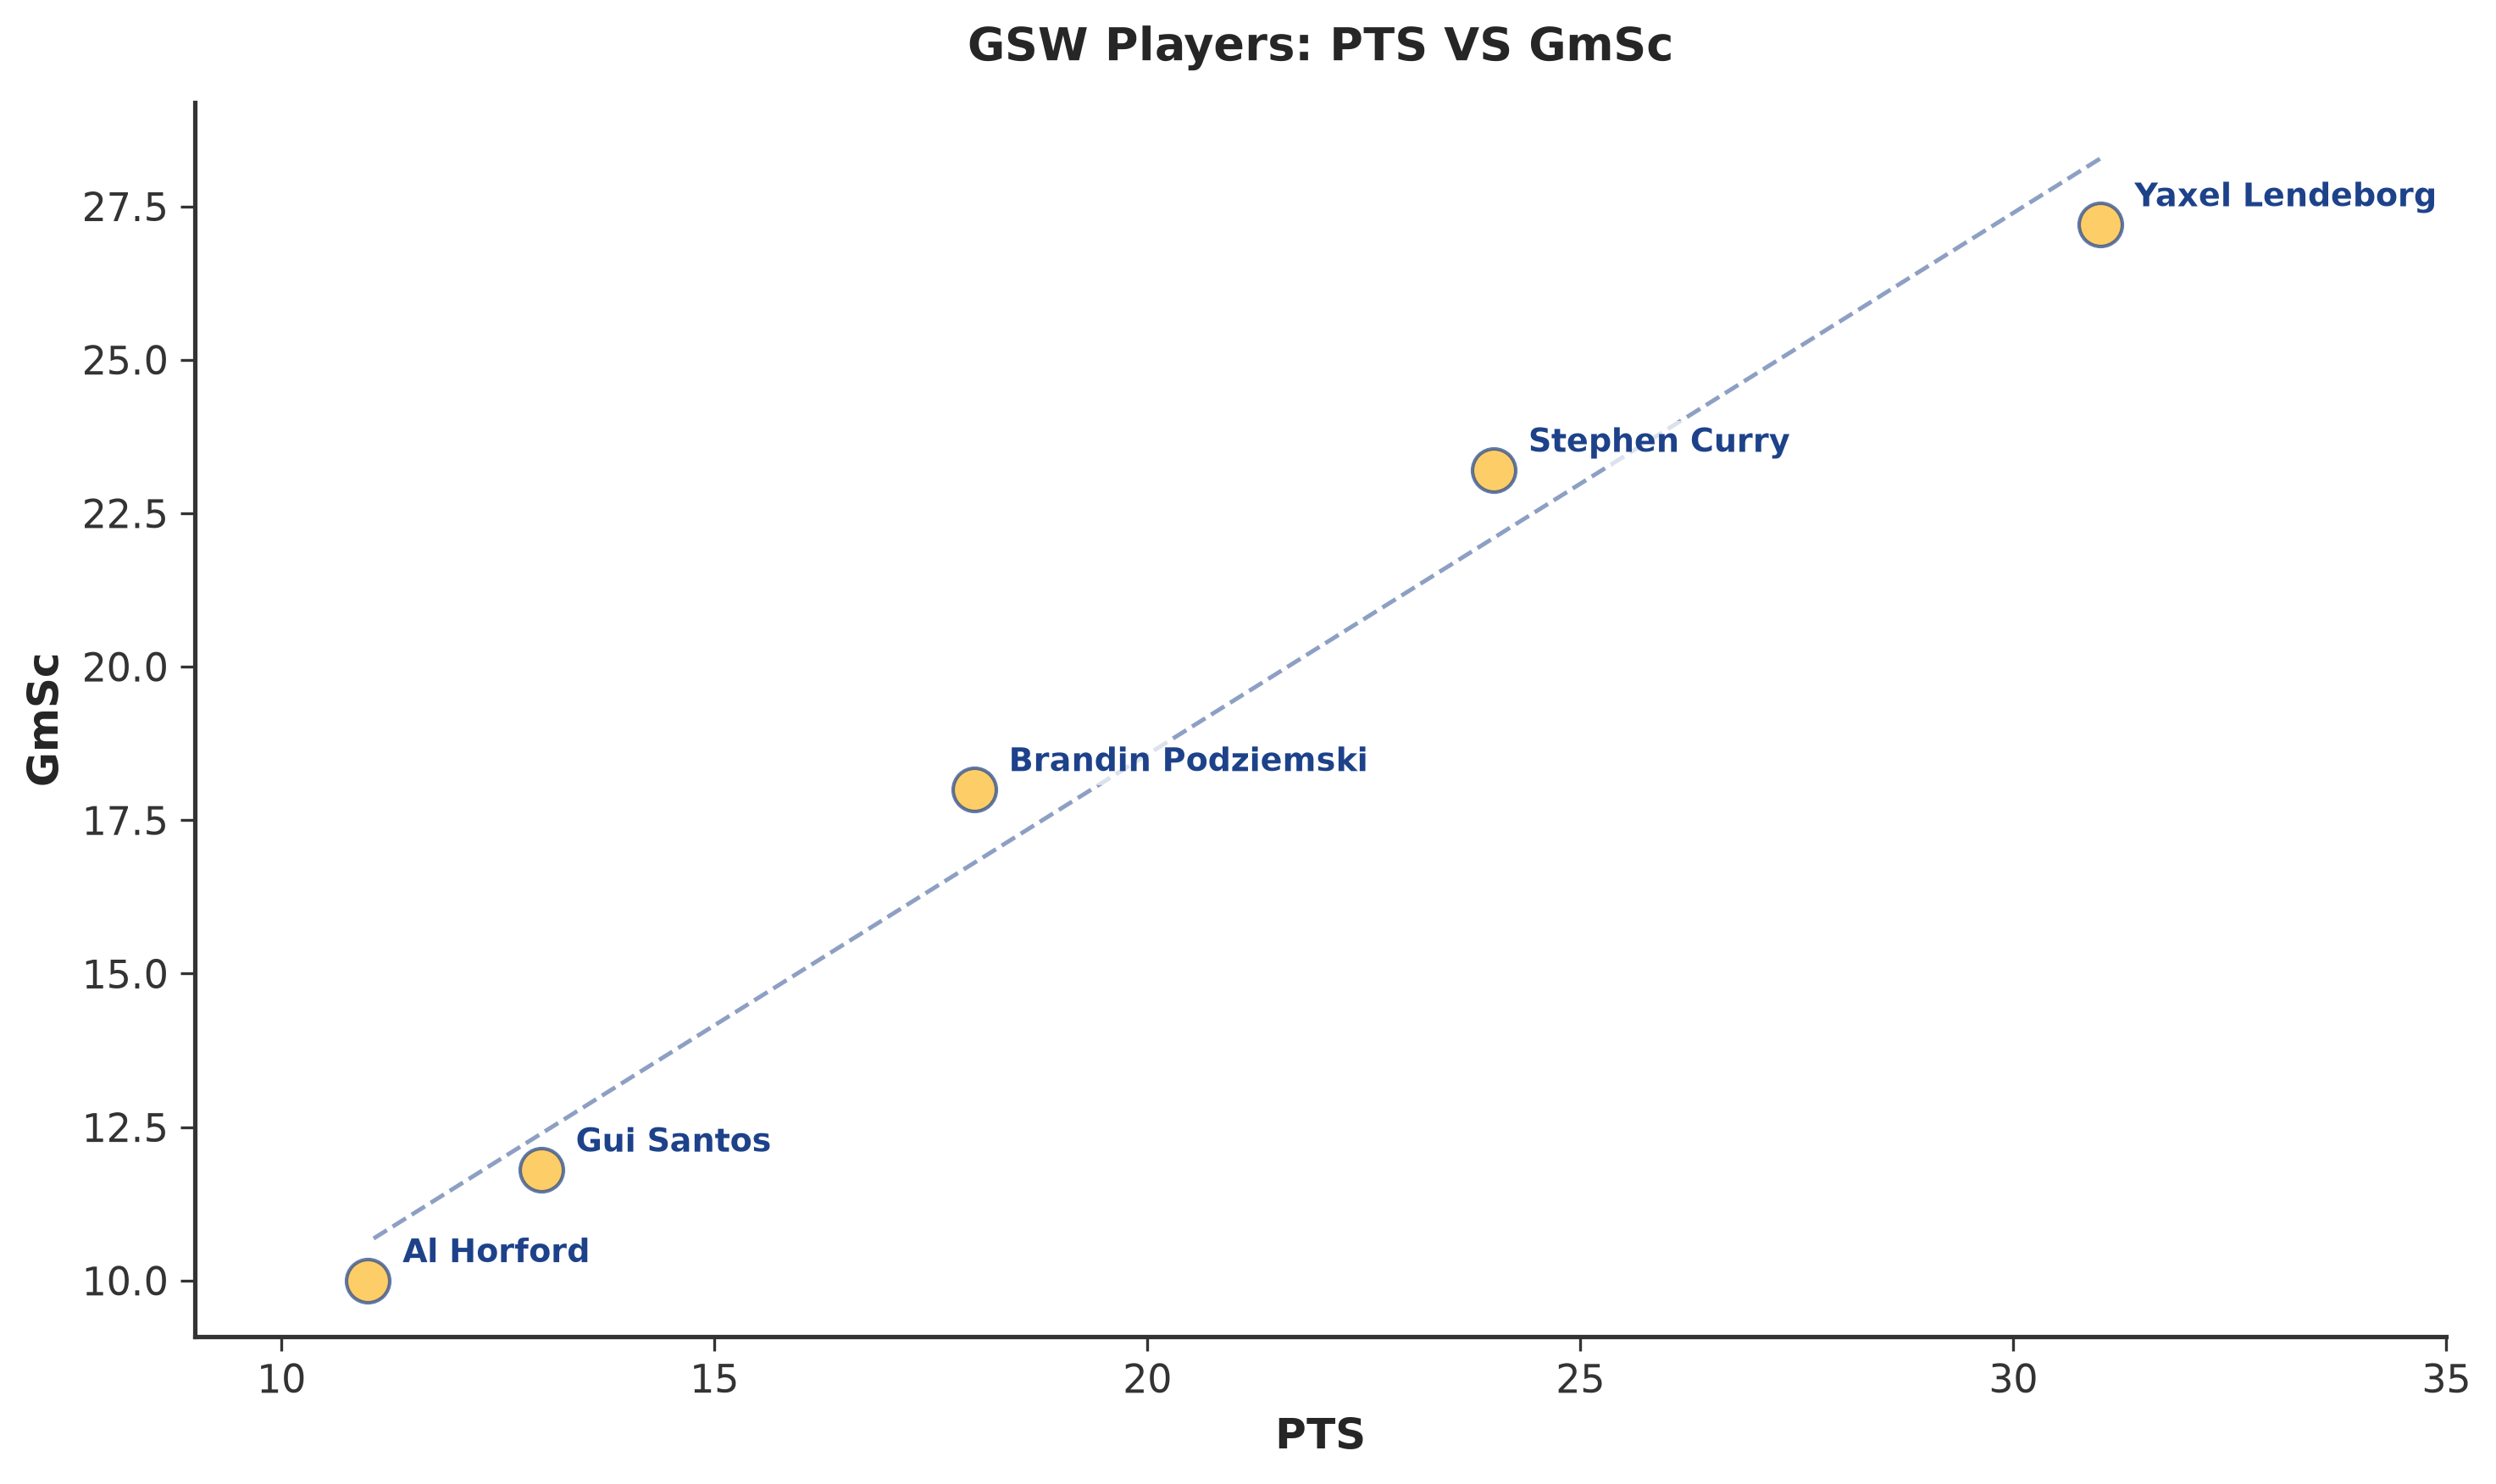

In [ ]:
#Making our Canvas for our Scatter Plot Graph ;)

fig, ax = plt.subplots(figsize=(10, 6))



players_top5iuu = df.nlargest(5,'PTS')

k,b = np.polyfit(players_top5iuu['PTS'], players_top5iuu['GmSc'],deg = 1)

line_regression = k * players_top5iuu['PTS'] + b 

ax.plot(
    players_top5iuu['PTS'],
    line_regression,
    color = GSW_BLUE,
    linestyle='--',
    linewidth=1.2,  
    alpha=0.5,
    zorder=1,
    label='Lineiuu'

)

#Removing top and right frames :)
sns.despine(top=True, right=True)



ax.scatter(
        players_top5iuu['PTS'], 
        players_top5iuu['GmSc'], 
        s=150, 
        color= GSW_GOLD, 
        edgecolors= GSW_BLUE, 
        linewidth=1, 
        alpha=0.7, 
        zorder=2
)

ax.set_xlim(players_top5iuu['PTS'].min() - 2, players_top5iuu['PTS'].max() + 4)

for idx, row in players_top5iuu.iterrows():
    ax.annotate(
        row['Player'],
        (row['PTS'] + 0.4, row['GmSc'] + 0.3),
        fontsize=9,
        fontweight='bold',
        color=GSW_BLUE,
        zorder=3,
        bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor='none', alpha=0.7)
    )

ax.set_title('GSW TOP 5 Players: PTS VS GmSc', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('PTS', fontsize=12, fontweight='semibold')
ax.set_ylabel('GmSc', fontsize=12, fontweight='semibold')


plt.tight_layout()
plt.savefig(FIGURES_DIR / "gsw_pts_vs_gmsc_iuu.png", bbox_inches='tight')
plt.show()
#ax.plot - plot is function that can help us to draw linear graph(draw some lines :) )
